# Vehicle Insurance Fraud Detection: EDA, Data Cleaning & Predictive Modeling

**Dataset:** Vehicle Insurance Claim Fraud Detection (15,420 real claims)
**Source:** Kaggle - shivamb/vehicle-claim-fraud-detection (also known as the "carclaims" dataset)

**Goal:** clean and explore this dataset, then build a model that predicts fraudulent claims (`FraudFound_P`). Every data quality issue found along the way is documented, along with the reasoning behind each cleaning and modeling decision.

## 1. Setup & Data Loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score,
    precision_recall_curve, auc, roc_curve, precision_score, recall_score, f1_score
)

try:
    from xgboost import XGBClassifier
    HAS_XGB = True
except ImportError:
    HAS_XGB = False
    from sklearn.ensemble import HistGradientBoostingClassifier

try:
    from imblearn.over_sampling import SMOTE
    HAS_SMOTE = True
except ImportError:
    HAS_SMOTE = False

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("XGBoost available:", HAS_XGB)
print("imbalanced-learn (SMOTE) available:", HAS_SMOTE)

XGBoost available: True
imbalanced-learn (SMOTE) available: True


In [2]:
df = pd.read_csv('fraud_oracle.csv')
print(f"Shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
df.head()

Shape: 15,420 rows x 33 columns


,Month,WeekOfMonth,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,WeekOfMonthClaimed,Sex,MaritalStatus,Age,Fault,PolicyType,VehicleCategory,VehiclePrice,FraudFound_P,PolicyNumber,RepNumber,Deductible,DriverRating,Days_Policy_Accident,Days_Policy_Claim,PastNumberOfClaims,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,Year,BasePolicy
0,Dec,5,Wednesday,Honda,Urban,Tuesday,Jan,1,Female,Single,21,Policy Holder,Sport - Liability,Sport,more than 69000,0,1,12,300,1,more than 30,more than 30,none,3 years,26 to 30,No,No,External,none,1 year,3 to 4,1994,Liability
1,Jan,3,Wednesday,Honda,Urban,Monday,Jan,4,Male,Single,34,Policy Holder,Sport - Collision,Sport,more than 69000,0,2,15,400,4,more than 30,more than 30,none,6 years,31 to 35,Yes,No,External,none,no change,1 vehicle,1994,Collision
2,Oct,5,Friday,Honda,Urban,Thursday,Nov,2,Male,Married,47,Policy Holder,Sport - Collision,Sport,more than 69000,0,3,7,400,3,more than 30,more than 30,1,7 years,41 to 50,No,No,External,none,no change,1 vehicle,1994,Collision
3,Jun,2,Saturday,Toyota,Rural,Friday,Jul,1,Male,Married,65,Third Party,Sedan - Liability,Sport,20000 to 29000,0,4,4,400,2,more than 30,more than 30,1,more than 7,51 to 65,Yes,No,External,more than 5,no change,1 vehicle,1994,Liability
4,Jan,5,Monday,Honda,Urban,Tuesday,Feb,2,Female,Single,27,Third Party,Sport - Collision,Sport,more than 69000,0,5,3,400,1,more than 30,more than 30,none,5 years,31 to 35,No,No,External,none,no change,1 vehicle,1994,Collision


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15420 entries, 0 to 15419
Data columns (total 33 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Month                 15420 non-null  str  
 1   WeekOfMonth           15420 non-null  int64
 2   DayOfWeek             15420 non-null  str  
 3   Make                  15420 non-null  str  
 4   AccidentArea          15420 non-null  str  
 5   DayOfWeekClaimed      15420 non-null  str  
 6   MonthClaimed          15420 non-null  str  
 7   WeekOfMonthClaimed    15420 non-null  int64
 8   Sex                   15420 non-null  str  
 9   MaritalStatus         15420 non-null  str  
 10  Age                   15420 non-null  int64
 11  Fault                 15420 non-null  str  
 12  PolicyType            15420 non-null  str  
 13  VehicleCategory       15420 non-null  str  
 14  VehiclePrice          15420 non-null  str  
 15  FraudFound_P          15420 non-null  int64
 16  PolicyNumber   

In [4]:
print("Numeric feature summary:")
display(df.describe())

print("\nCategorical feature summary:")
display(df.describe(include='object'))

Numeric feature summary:


,WeekOfMonth,WeekOfMonthClaimed,Age,FraudFound_P,PolicyNumber,RepNumber,Deductible,DriverRating,Year
count,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000,15420.000000
mean,2.788586,2.693969,39.855707,0.059857,7710.500000,8.483268,407.704280,2.487808,1994.866472
std,1.287585,1.259115,13.492377,0.237230,4451.514911,4.599948,43.950998,1.119453,0.803313
min,1.000000,1.000000,0.000000,0.000000,1.000000,1.000000,300.000000,1.000000,1994.000000
25%,2.000000,2.000000,31.000000,0.000000,3855.750000,5.000000,400.000000,1.000000,1994.000000
50%,3.000000,3.000000,38.000000,0.000000,7710.500000,8.000000,400.000000,2.000000,1995.000000
75%,4.000000,4.000000,48.000000,0.000000,11565.250000,12.000000,400.000000,3.000000,1996.000000
max,5.000000,5.000000,80.000000,1.000000,15420.000000,16.000000,700.000000,4.000000,1996.000000



Categorical feature summary:


C:\Users\HP\AppData\Local\Temp\ipykernel_23468\243073108.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include='object'))


,Month,DayOfWeek,Make,AccidentArea,DayOfWeekClaimed,MonthClaimed,Sex,MaritalStatus,Fault,PolicyType,VehicleCategory,VehiclePrice,Days_Policy_Accident,Days_Policy_Claim,PastNumberOfClaims,AgeOfVehicle,AgeOfPolicyHolder,PoliceReportFiled,WitnessPresent,AgentType,NumberOfSuppliments,AddressChange_Claim,NumberOfCars,BasePolicy
count,15420,15420,15420,15420,15420,15420,15420,15420,15420,15420,15420,15420,15420,15420,15420,15420,15420,15420,15420,15420,15420,15420,15420,15420
unique,12,7,19,2,8,13,2,4,2,9,3,6,5,4,4,8,9,2,2,2,4,5,5,3
top,Jan,Monday,Pontiac,Urban,Monday,Jan,Male,Married,Policy Holder,Sedan - Collision,Sedan,20000 to 29000,more than 30,more than 30,2 to 4,7 years,31 to 35,No,No,External,none,no change,1 vehicle,Collision
freq,1411,2616,3837,13822,3757,1446,13000,10625,11230,5584,9671,8079,15247,15342,5485,5807,5593,14992,15333,15179,7047,14324,14316,5962


## 2. Data Quality Audit

At first glance this dataset looks clean - no `NaN` values, no exact duplicate rows. But that doesn't mean there are no data quality issues. A lot of real-world data hides missing values behind sentinel values instead of actual nulls - placeholder entries that look like valid data but aren't. That turns out to be exactly what's going on here, so we dig past the basic `.isnull()` check.

### 2.1 Surface-Level Check: NaNs & Duplicates

In [5]:
print("Total NaN values:", df.isnull().sum().sum())
print("Fully duplicated rows:", df.duplicated().sum())
print("Duplicated PolicyNumber values:", df['PolicyNumber'].duplicated().sum())

Total NaN values: 0


Fully duplicated rows: 0
Duplicated PolicyNumber values: 0


### 2.2 Hidden Missingness: Sentinel Values

We check numeric columns for implausible values (like an age of 0) and categorical columns for placeholder categories that don't belong among genuine categories.

In [6]:
age_zero_count = (df['Age'] == 0).sum()
print(f"Rows with Age == 0: {age_zero_count} ({age_zero_count/len(df)*100:.2f}%)")
print("An age of 0 is not a valid policyholder age — this is almost certainly a masked missing value,")
print("not a genuine data point.\n")

print("DayOfWeekClaimed unique values:", df['DayOfWeekClaimed'].unique())
print("MonthClaimed unique values:", df['MonthClaimed'].unique())
print()
print(f"Rows with DayOfWeekClaimed == '0': {(df['DayOfWeekClaimed'] == '0').sum()}")
print(f"Rows with MonthClaimed == '0': {(df['MonthClaimed'] == '0').sum()}")

Rows with Age == 0: 320 (2.08%)
An age of 0 is not a valid policyholder age — this is almost certainly a masked missing value,
not a genuine data point.

DayOfWeekClaimed unique values: <StringArray>
[  'Tuesday',    'Monday',  'Thursday',    'Friday', 'Wednesday',  'Saturday',
    'Sunday',         '0']
Length: 8, dtype: str
MonthClaimed unique values: <StringArray>
['Jan', 'Nov', 'Jul', 'Feb', 'Mar', 'Dec', 'Apr', 'Aug', 'May', 'Jun', 'Sep',
 'Oct',   '0']
Length: 13, dtype: str

Rows with DayOfWeekClaimed == '0': 1
Rows with MonthClaimed == '0': 1


**What we found:**
- `Age == 0` shows up in 320 rows (2.08%). No policyholder is actually age 0, so this has to be a masked missing value - one that `.isnull()` would never catch.
- `DayOfWeekClaimed`/`MonthClaimed == '0'` shows up in exactly 1 row. That's a single corrupted record rather than a systemic problem (both fields are `'0'` on the same row, which looks like a claim that was never properly filed). We'll just drop this row instead of trying to impute it.

### 2.3 Format Inconsistency: Numeric Concepts Stored as Text Bins

A handful of columns represent things that are really numeric or ordinal - age brackets, day ranges - but they're stored as free-text labels like "more than 30". That's not missing data, but it is a format problem we need to fix before modeling, since a model can't treat "more than 30" as a number without us encoding it first.

In [7]:
ordinal_bin_cols = ['Days_Policy_Accident', 'Days_Policy_Claim', 'AgeOfVehicle', 'AgeOfPolicyHolder',
                     'PastNumberOfClaims', 'NumberOfSuppliments', 'AddressChange_Claim', 'NumberOfCars']

for col in ordinal_bin_cols:
    print(f"{col}: {sorted(df[col].unique())}")

Days_Policy_Accident: ['1 to 7', '15 to 30', '8 to 15', 'more than 30', 'none']
Days_Policy_Claim: ['15 to 30', '8 to 15', 'more than 30', 'none']
AgeOfVehicle: ['2 years', '3 years', '4 years', '5 years', '6 years', '7 years', 'more than 7', 'new']
AgeOfPolicyHolder: ['16 to 17', '18 to 20', '21 to 25', '26 to 30', '31 to 35', '36 to 40', '41 to 50', '51 to 65', 'over 65']
PastNumberOfClaims: ['1', '2 to 4', 'more than 4', 'none']
NumberOfSuppliments: ['1 to 2', '3 to 5', 'more than 5', 'none']
AddressChange_Claim: ['1 year', '2 to 3 years', '4 to 8 years', 'no change', 'under 6 months']
NumberOfCars: ['1 vehicle', '2 vehicles', '3 to 4', '5 to 8', 'more than 8']


### 2.4 Internal Consistency Check: `PolicyType` vs `VehicleCategory` / `BasePolicy`

`PolicyType` looks like it should just be `VehicleCategory + " - " + BasePolicy` (e.g. "Sport - Liability"). If that's true, one of these columns is redundant. Let's check.

In [8]:
df['PT_category'] = df['PolicyType'].str.split(' - ').str[0]
df['PT_basepolicy'] = df['PolicyType'].str.split(' - ').str[1]

basepolicy_mismatch = (df['PT_basepolicy'] != df['BasePolicy']).sum()
category_mismatch = (df['PT_category'] != df['VehicleCategory']).sum()

print(f"PolicyType's base-policy part vs BasePolicy column -- mismatches: {basepolicy_mismatch}")
print(f"PolicyType's category part vs VehicleCategory column -- mismatches: {category_mismatch} "
      f"({category_mismatch/len(df)*100:.1f}%)")

PolicyType's base-policy part vs BasePolicy column -- mismatches: 0
PolicyType's category part vs VehicleCategory column -- mismatches: 4987 (32.3%)


**What we found:** the category embedded in `PolicyType` matches `BasePolicy` perfectly (0 mismatches), but it disagrees with the standalone `VehicleCategory` column on 4,987 rows - 32.3% of the data. That's way too many to be typos. Since `PolicyType` lines up with `BasePolicy` and `VehicleCategory` doesn't, we're going to trust `PolicyType`'s version of the category and drop the standalone `VehicleCategory` column when we clean the data.

## 3. Data Cleaning

Each fix below follows directly from something we found in Section 2. Row counts are printed before and after each step so the changes are traceable.

### 3.1 Drop the Single Corrupted Record

In [9]:
df_clean = df.copy()
rows_before = len(df_clean)

df_clean = df_clean[df_clean['MonthClaimed'] != '0'].copy()

print(f"Rows before: {rows_before:,}")
print(f"Rows after: {len(df_clean):,}")
print(f"Rows removed: {rows_before - len(df_clean)}")

Rows before: 15,420
Rows after: 15,419
Rows removed: 1


### 3.2 Fix Masked Missing Ages

Digging a bit further: every single one of the 320 `Age == 0` rows falls in the `AgeOfPolicyHolder == "16 to 17"` bracket, no exceptions. So this isn't random missingness, it looks like a data entry convention - probably minors added to a parent's policy, where the exact age wasn't recorded but the coarser bracket was.

Since we know the bracket and it only spans two possible ages, we fill `Age` in with 17 (the upper end of the bracket) instead of using some broader dataset-wide median, which would just pull these rows toward the overall average age (around 40) and throw away information we already have.

In [10]:
# Verify the claim before acting on it
bracket_check = df_clean.loc[df_clean['Age'] == 0, 'AgeOfPolicyHolder'].value_counts()
print("AgeOfPolicyHolder bracket for all Age==0 rows:")
print(bracket_check)
assert (df_clean.loc[df_clean['Age'] == 0, 'AgeOfPolicyHolder'] == '16 to 17').all(), \
    "Unexpected: not all Age==0 rows are in the '16 to 17' bracket"

df_clean.loc[df_clean['Age'] == 0, 'Age'] = 17

print(f"\nRemaining Age == 0 rows: {(df_clean['Age'] == 0).sum()}")
print(f"Age range after fix: {df_clean['Age'].min()} - {df_clean['Age'].max()}")

AgeOfPolicyHolder bracket for all Age==0 rows:
AgeOfPolicyHolder
16 to 17    319
Name: count, dtype: int64



Remaining Age == 0 rows: 0
Age range after fix: 16 - 80


### 3.3 Ordinal-Encode Text-Bin Columns

These columns have a natural order to them ("none" < "1" < "2 to 4" < "more than 4"), so we map each one to integers that preserve that order. That way models can treat them as ordered numeric signals instead of unrelated categories, and they can also be included in the correlation heatmap later.

In [11]:
ordinal_maps = {
    'Days_Policy_Accident': {'none': 0, '1 to 7': 1, '8 to 15': 2, '15 to 30': 3, 'more than 30': 4},
    'Days_Policy_Claim':    {'none': 0, '8 to 15': 1, '15 to 30': 2, 'more than 30': 3},
    'AgeOfVehicle':         {'new': 0, '2 years': 1, '3 years': 2, '4 years': 3, '5 years': 4,
                              '6 years': 5, '7 years': 6, 'more than 7': 7},
    'AgeOfPolicyHolder':    {'16 to 17': 0, '18 to 20': 1, '21 to 25': 2, '26 to 30': 3, '31 to 35': 4,
                              '36 to 40': 5, '41 to 50': 6, '51 to 65': 7, 'over 65': 8},
    'PastNumberOfClaims':   {'none': 0, '1': 1, '2 to 4': 2, 'more than 4': 3},
    'NumberOfSuppliments':  {'none': 0, '1 to 2': 1, '3 to 5': 2, 'more than 5': 3},
    'AddressChange_Claim':  {'no change': 0, 'under 6 months': 1, '1 year': 2, '2 to 3 years': 3, '4 to 8 years': 4},
    'NumberOfCars':         {'1 vehicle': 0, '2 vehicles': 1, '3 to 4': 2, '5 to 8': 3, 'more than 8': 4},
}

for col, mapping in ordinal_maps.items():
    # The mapping must cover every category present in the data (not necessarily the reverse —
    # a category can legitimately disappear from df_clean after the Section 3.1 row drop, as
    # happened with Days_Policy_Claim's 'none' category, which existed only in the dropped row).
    present_categories = set(df_clean[col].unique())
    mapped_categories = set(mapping.keys())
    missing_from_map = present_categories - mapped_categories
    assert not missing_from_map, f"Mismatch in {col}: {missing_from_map} present in data but not mapped"
    df_clean[col + '_ord'] = df_clean[col].map(mapping)

print("Ordinal encoding applied. Example:")
df_clean[['Days_Policy_Accident', 'Days_Policy_Accident_ord', 'AgeOfPolicyHolder', 'AgeOfPolicyHolder_ord']].head()

Ordinal encoding applied. Example:

,Days_Policy_Accident,Days_Policy_Accident_ord,AgeOfPolicyHolder,AgeOfPolicyHolder_ord
0,more than 30,4,26 to 30,3
1,more than 30,4,31 to 35,4
2,more than 30,4,41 to 50,6
3,more than 30,4,51 to 65,7
4,more than 30,4,31 to 35,4


### 3.4 Resolve `VehicleCategory` Inconsistency

Swap out the unreliable `VehicleCategory` column for the category embedded in `PolicyType` (see Section 2.4), then drop the original.

In [12]:
df_clean['VehicleCategory_clean'] = df_clean['PolicyType'].str.split(' - ').str[0]
df_clean = df_clean.drop(columns=['VehicleCategory'])

print("New VehicleCategory_clean distribution:")
print(df_clean['VehicleCategory_clean'].value_counts())

New VehicleCategory_clean distribution:
VehicleCategory_clean
Sedan      14657
Utility      391
Sport        371
Name: count, dtype: int64


In [13]:
print("=== CLEANING SUMMARY ===")
print(f"Original shape: {df.shape}")
print(f"Cleaned shape:  {df_clean.shape}")
print(f"Rows removed (corrupted record): {df.shape[0] - df_clean.shape[0]}")
print(f"Age==0 rows fixed: 320")
print(f"VehicleCategory inconsistencies resolved: {category_mismatch:,} rows")
print(f"Fraud rate (cleaned): {df_clean['FraudFound_P'].mean()*100:.2f}%")

=== CLEANING SUMMARY ===
Original shape: (15420, 35)
Cleaned shape:  (15419, 43)
Rows removed (corrupted record): 1
Age==0 rows fixed: 320
VehicleCategory inconsistencies resolved: 4,987 rows
Fraud rate (cleaned): 5.99%


## 4. Exploratory Data Analysis

### 4.1 Class Imbalance

C:\Users\HP\AppData\Local\Temp\ipykernel_23468\285721266.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=fraud_counts.index.map({0: 'Legitimate', 1: 'Fraudulent'}), y=fraud_counts.values,


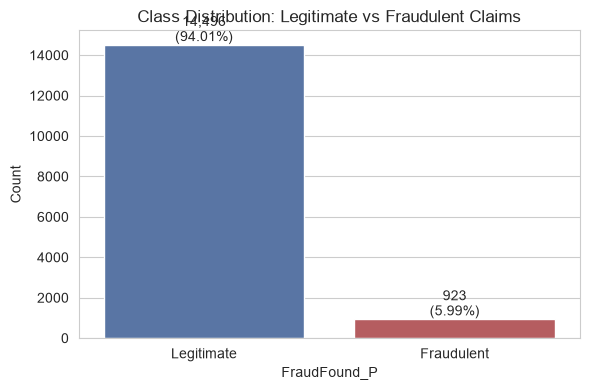

Fraud rate: 5.99%
A model predicting 'not fraud' for every claim would score ~94.0% accuracy while catching 0% of fraud — accuracy alone is not a meaningful metric here.


In [14]:
fraud_counts = df_clean['FraudFound_P'].value_counts()
fraud_pct = df_clean['FraudFound_P'].value_counts(normalize=True) * 100

fig, ax = plt.subplots(figsize=(6, 4))
sns.barplot(x=fraud_counts.index.map({0: 'Legitimate', 1: 'Fraudulent'}), y=fraud_counts.values,
            palette=['#4C72B0', '#C44E52'], ax=ax)
for i, (count, pct) in enumerate(zip(fraud_counts.values, fraud_pct.values)):
    ax.text(i, count + 200, f"{count:,}\n({pct:.2f}%)", ha='center')
ax.set_ylabel('Count')
ax.set_title('Class Distribution: Legitimate vs Fraudulent Claims')
plt.tight_layout()
plt.show()

print(f"Fraud rate: {fraud_pct[1]:.2f}%")
print(f"A model predicting 'not fraud' for every claim would score ~{fraud_pct[0]:.1f}% accuracy "
      "while catching 0% of fraud — accuracy alone is not a meaningful metric here.")

### 4.2 Fraud Rate by Key Features

Instead of formal statistical tests, we just look at fraud rate broken down by the features that make intuitive sense as fraud indicators - who was at fault, the type of vehicle, the policy type, and the claimed price - and see what the charts show.

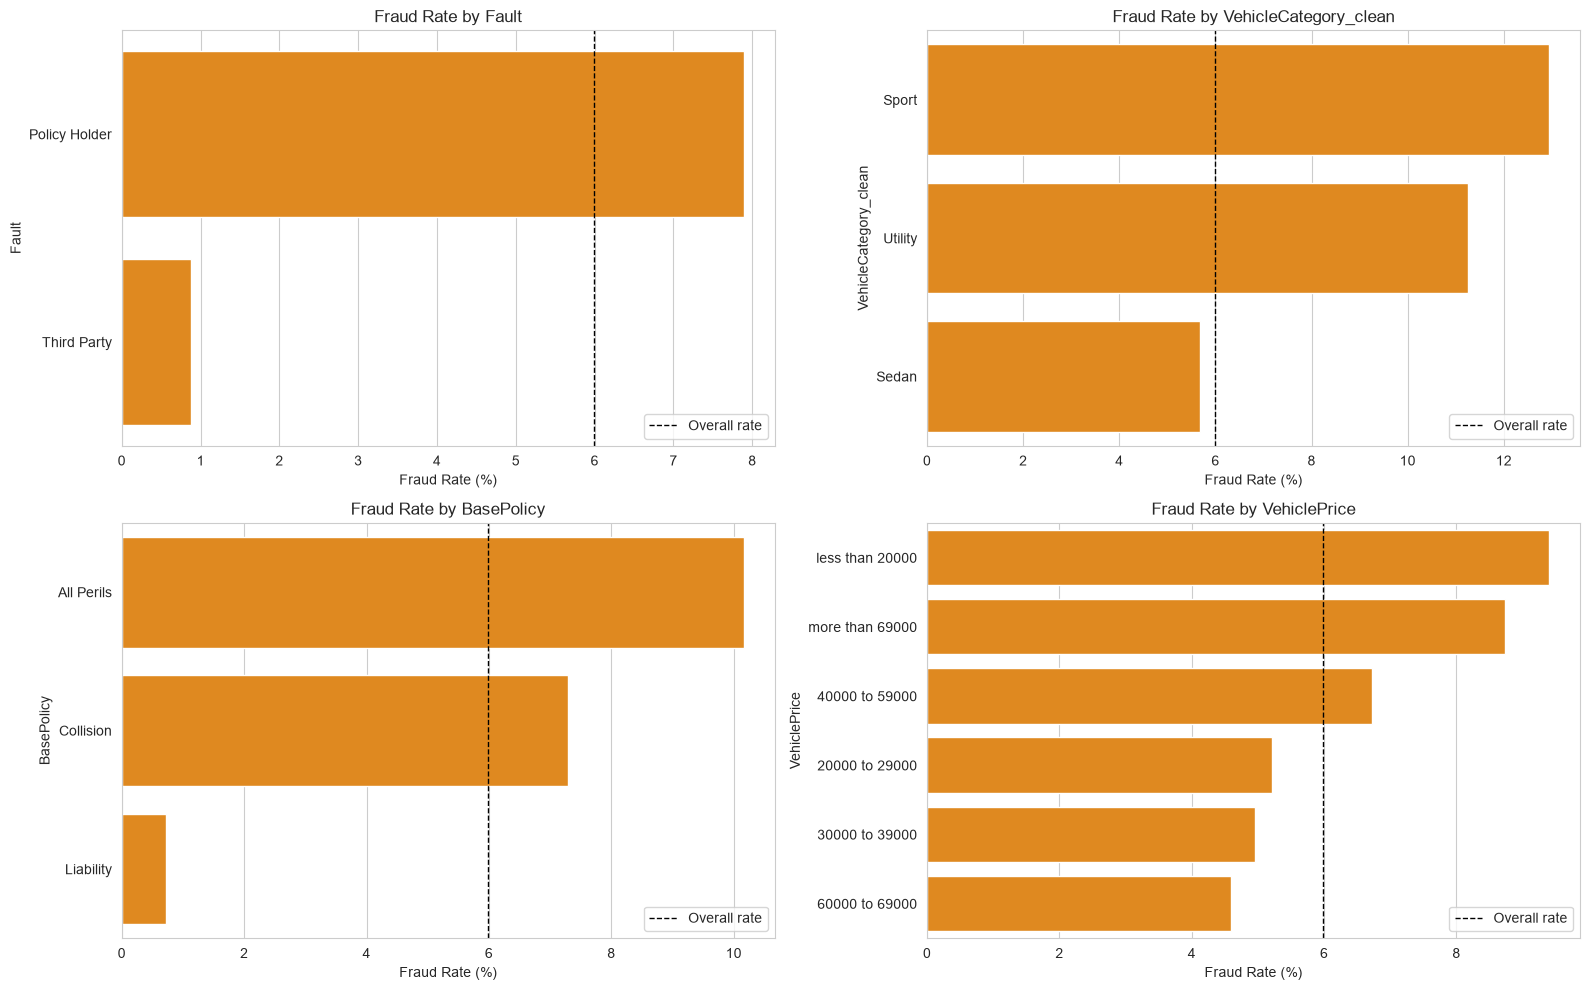

In [15]:
top_categorical = ['Fault', 'VehicleCategory_clean', 'BasePolicy', 'VehiclePrice']

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for ax, col in zip(axes, top_categorical):
    rate = df_clean.groupby(col)['FraudFound_P'].mean().sort_values(ascending=False) * 100
    sns.barplot(x=rate.values, y=rate.index, ax=ax, color='darkorange')
    ax.axvline(df_clean['FraudFound_P'].mean() * 100, color='black', linestyle='--', linewidth=1, label='Overall rate')
    ax.set_xlabel('Fraud Rate (%)')
    ax.set_title(f'Fraud Rate by {col}')
    ax.legend()

plt.tight_layout()
plt.show()

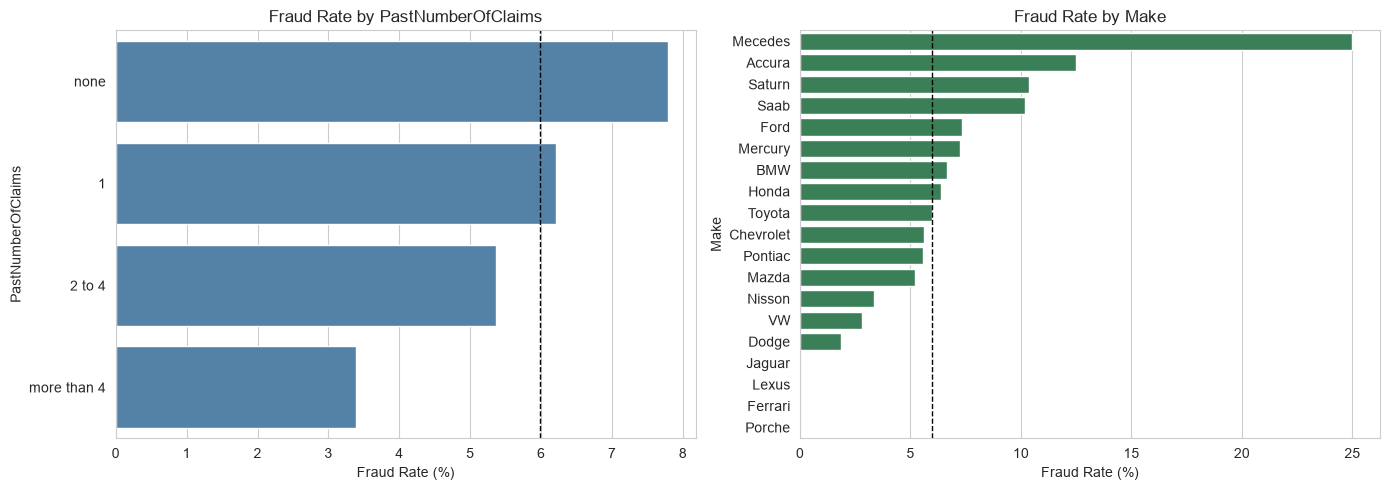

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

rate = df_clean.groupby('PastNumberOfClaims')['FraudFound_P'].mean().sort_values(ascending=False) * 100
sns.barplot(x=rate.values, y=rate.index, ax=axes[0], color='steelblue')
axes[0].axvline(df_clean['FraudFound_P'].mean() * 100, color='black', linestyle='--', linewidth=1)
axes[0].set_xlabel('Fraud Rate (%)')
axes[0].set_title('Fraud Rate by PastNumberOfClaims')

rate2 = df_clean.groupby('Make')['FraudFound_P'].mean().sort_values(ascending=False) * 100
sns.barplot(x=rate2.values, y=rate2.index, ax=axes[1], color='seagreen')
axes[1].axvline(df_clean['FraudFound_P'].mean() * 100, color='black', linestyle='--', linewidth=1)
axes[1].set_xlabel('Fraud Rate (%)')
axes[1].set_title('Fraud Rate by Make')

plt.tight_layout()
plt.show()

**What the charts show:**
- `Fault` is the clearest signal here: fraud rate is 7.89% when the policyholder is at fault, versus just 0.88% when a third party is at fault - almost a 9x gap. That tracks with intuition: a policyholder who caused the accident has an actual financial motive to inflate or fabricate the claim, while a third-party-fault claim usually gets corroborated externally.
- Vehicle category (cleaned) also matters: Sport (12.9%) and Utility (11.3%) vehicles have much higher fraud rates than Sedans (5.7%), which lines up with the idea that pricier, more expensive-to-repair vehicles are more attractive targets for staged claims.
- `PastNumberOfClaims` gives a genuinely surprising result: claimants with *no* prior claims history actually have the highest fraud rate (7.8%), while people with more than 4 past claims have the lowest (3.4%). Worth calling out rather than glossing over, since the intuitive assumption would be the opposite. One possible explanation: repeat legitimate claimants already have a track record insurers trust, while first-time claimants filing something unusual stand out more. We're not claiming a causal reason here, just reporting what the data shows.

### 4.3 Correlation Among Numeric / Ordinal Features

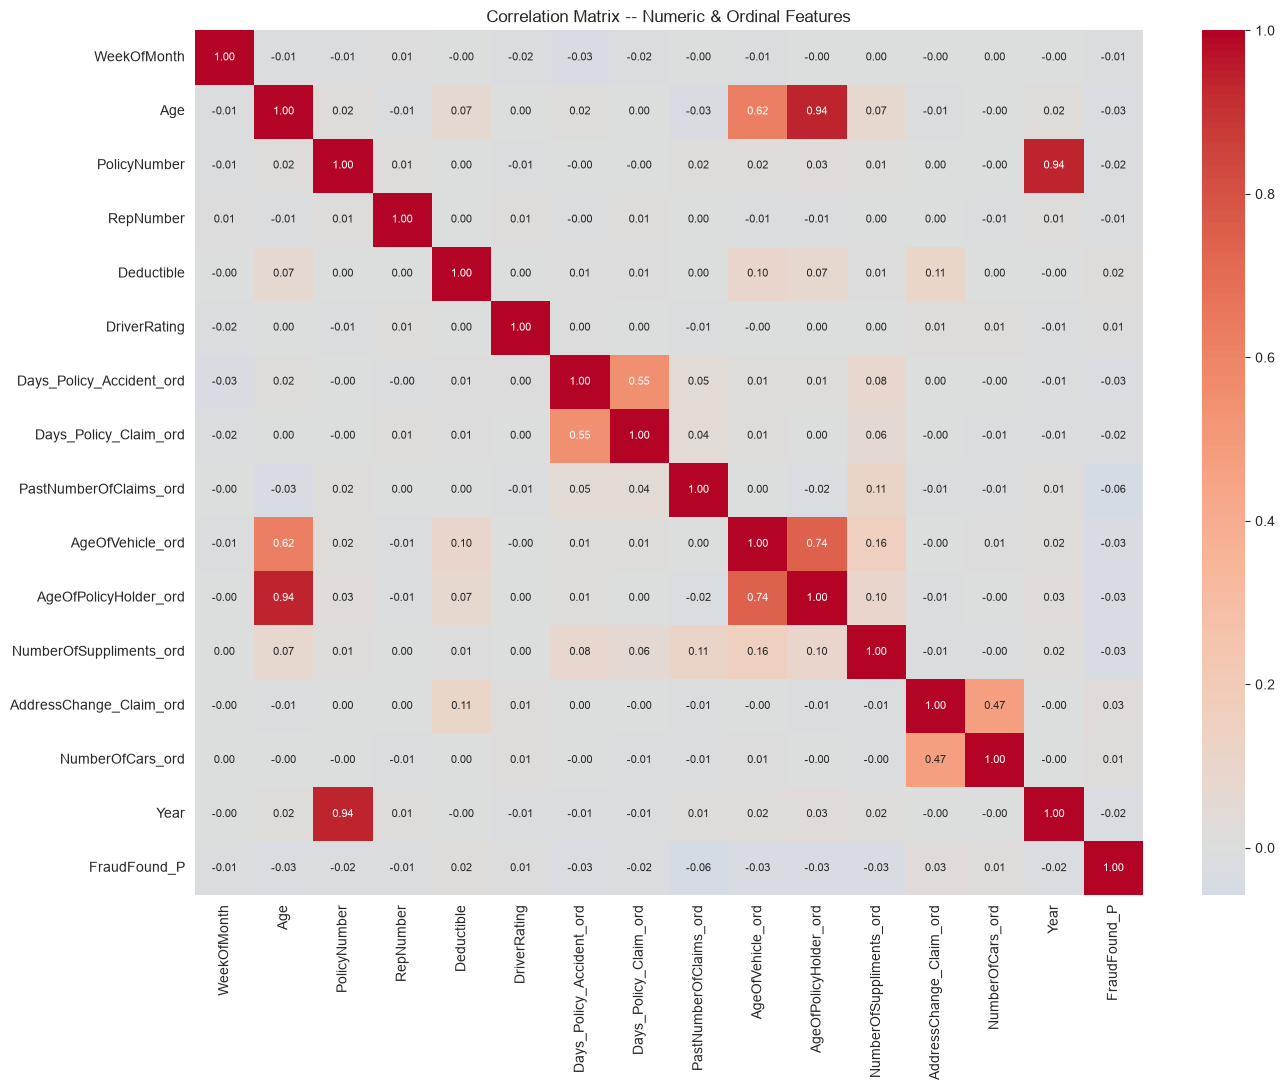

In [17]:
numeric_features = ['WeekOfMonth', 'Age', 'PolicyNumber', 'RepNumber', 'Deductible', 'DriverRating',
                     'Days_Policy_Accident_ord', 'Days_Policy_Claim_ord', 'PastNumberOfClaims_ord',
                     'AgeOfVehicle_ord', 'AgeOfPolicyHolder_ord', 'NumberOfSuppliments_ord',
                     'AddressChange_Claim_ord', 'NumberOfCars_ord', 'Year']

corr_cols = numeric_features + ['FraudFound_P']
corr_matrix = df_clean[corr_cols].corr()

fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax,
            annot_kws={'size': 8})
ax.set_title('Correlation Matrix -- Numeric & Ordinal Features')
plt.tight_layout()
plt.show()

**Note:** `PolicyNumber` is just a sequential ID, not a real feature, so we leave it out of modeling - otherwise the model could latch onto it as a shortcut instead of learning actual fraud patterns.

## 5. Feature Engineering

The three features below all come directly from what Section 4 showed us about this specific dataset, rather than a generic checklist.

### 5.1 `is_policyholder_fault`

A binary version of `Fault` (1 = Policy Holder at fault, 0 = Third Party at fault). We saw in Section 4.2 that this is the strongest single predictor of fraud, so encoding it explicitly as a clean binary makes that signal directly usable, especially for Logistic Regression.

In [18]:
df_clean['is_policyholder_fault'] = (df_clean['Fault'] == 'Policy Holder').astype(int)
print(df_clean.groupby('is_policyholder_fault')['FraudFound_P'].mean() * 100)

is_policyholder_fault
0    0.883055
1    7.890284
Name: FraudFound_P, dtype: float64


### 5.2 `is_extreme_vehicle_price`

`VehiclePrice` doesn't have a simple linear relationship with fraud, it's more U-shaped: both "less than 20000" (9.4%) and "more than 69000" (8.7%) have noticeably higher fraud rates than the mid-range price bins (4.6%-6.7%). A linear model can't really represent a U-shape with one ordinal variable, since it would need the coefficient to be positive and negative at the same time. Flagging the two extremes as a single binary feature makes that pattern directly learnable.

In [19]:
df_clean['is_extreme_vehicle_price'] = df_clean['VehiclePrice'].isin(['less than 20000', 'more than 69000']).astype(int)
print(df_clean.groupby('is_extreme_vehicle_price')['FraudFound_P'].mean() * 100)

is_extreme_vehicle_price
0    5.189145
1    8.959804
Name: FraudFound_P, dtype: float64


### 5.3 `fault_and_no_history` (Interaction Feature)

`is_policyholder_fault` and having no prior claims (`PastNumberOfClaims == 'none'`) are both strong signals on their own, and they might compound when they occur together. Random Forest and XGBoost can pick up on this kind of interaction automatically by splitting on both features in sequence, but Logistic Regression can't unless we hand it the interaction as its own column.

In [20]:
df_clean['fault_and_no_history'] = (
    (df_clean['Fault'] == 'Policy Holder') & (df_clean['PastNumberOfClaims'] == 'none')
).astype(int)

print(df_clean.groupby('fault_and_no_history')['FraudFound_P'].mean() * 100)
print(df_clean['fault_and_no_history'].value_counts())

fault_and_no_history
0     4.806846
1    11.042524
Name: FraudFound_P, dtype: float64
fault_and_no_history
0    12503
1     2916
Name: count, dtype: int64


## 6. Preprocessing for Modeling

### 6.1 Select & Encode Features

Columns we drop: `PolicyNumber` (an ID, not a feature), and `Fault`/`PastNumberOfClaims`/`AgeOfVehicle`/`AgeOfPolicyHolder`/`Days_Policy_Accident`/`Days_Policy_Claim`/`NumberOfSuppliments`/`AddressChange_Claim`/`NumberOfCars` since we already have their ordinal or engineered versions. We also drop `PolicyType` itself, since Section 3.4 already split it into `BasePolicy` and `VehicleCategory_clean`, so keeping the original would just be duplicating information.

`PT_category` and `PT_basepolicy` also get dropped - they were only ever temporary helper columns for the Section 2.4 investigation, not meant to be used in the model.

Everything else that's a nominal category gets one-hot encoded; the ordinal, engineered, and numeric columns are left as they are.

In [21]:
drop_cols = ['PolicyNumber', 'Fault', 'PastNumberOfClaims', 'AgeOfVehicle', 'AgeOfPolicyHolder',
             'Days_Policy_Accident', 'Days_Policy_Claim', 'NumberOfSuppliments', 'AddressChange_Claim',
             'NumberOfCars', 'PolicyType',
             'PT_category', 'PT_basepolicy']  # temporary helper cols from Section 2.4

nominal_categoricals = ['Month', 'DayOfWeek', 'Make', 'AccidentArea', 'DayOfWeekClaimed', 'MonthClaimed',
                         'Sex', 'MaritalStatus', 'BasePolicy', 'VehicleCategory_clean', 'VehiclePrice',
                         'PoliceReportFiled', 'WitnessPresent', 'AgentType']

model_df = df_clean.drop(columns=drop_cols)
model_df = pd.get_dummies(model_df, columns=nominal_categoricals, drop_first=True)

X = model_df.drop(columns=['FraudFound_P'])
y = model_df['FraudFound_P']

assert X.select_dtypes(include=['object', 'string']).columns.empty, \
    f"Non-numeric columns remain: {X.select_dtypes(include=['object', 'string']).columns.tolist()}"

print(f"Final feature matrix: {X.shape[0]:,} rows x {X.shape[1]} columns")
print(f"Target distribution: {y.value_counts().to_dict()}")


Final feature matrix: 15,419 rows x 87 columns
Target distribution: {0: 14496, 1: 923}


### 6.2 Train/Test Split

We use a stratified split rather than a time-based one. This dataset doesn't have a real transaction timestamp the way a payments dataset would - `Month`/`Year` describe when the accident happened, not a sequence of events we need to respect chronologically. Stratifying on `FraudFound_P` just makes sure both the train and test sets keep roughly the same fraud rate, which matters more than usual given how imbalanced this is (a plain random split could easily leave us with a test set that has very few fraud cases by chance).

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print(f"Train: {X_train.shape[0]:,} rows | Fraud rate: {y_train.mean()*100:.2f}%")
print(f"Test:  {X_test.shape[0]:,} rows | Fraud rate: {y_test.mean()*100:.2f}%")

Train: 12,335 rows | Fraud rate: 5.98%
Test:  3,084 rows | Fraud rate: 6.00%


### 6.3 Scaling

Logistic Regression is sensitive to feature scale, Random Forest and XGBoost aren't since they split on raw thresholds. We fit the scaler on the training data only and apply it to both sets, so nothing from the test set leaks into training.

In [23]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# scale_pos_weight for XGBoost: ratio of negative to positive class in the training set
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"scale_pos_weight (for XGBoost): {scale_pos_weight:.2f}")

scale_pos_weight (for XGBoost): 15.71


## 7. Modeling

**Models used:**
1. Logistic Regression - a simple, interpretable baseline. Its coefficients give a clear, explainable reason behind each prediction.
2. Random Forest - handles the mix of categorical and numeric features without needing scaling, holds up well against outliers, and gives us a second feature-importance ranking to compare against Logistic Regression's coefficients.
3. XGBoost (falls back to `HistGradientBoostingClassifier` if XGBoost isn't installed) - the standard choice for tabular fraud detection, and it handles class imbalance natively through `scale_pos_weight`.

**Handling the imbalance:** we use class weighting (`class_weight='balanced'` / `scale_pos_weight`) as the main approach, since it only reweights the real training examples rather than inventing new ones. We also fit one Logistic Regression with SMOTE instead, just to compare the two approaches directly rather than assuming one is better.

### 7.1 Train Models

In [24]:
models = {}

# 1. Logistic Regression (class-weighted, scaled features)
models['Logistic Regression'] = LogisticRegression(
    class_weight='balanced', max_iter=1000, random_state=RANDOM_STATE
).fit(X_train_scaled, y_train)

# 2. Random Forest (class-weighted, raw features)
models['Random Forest'] = RandomForestClassifier(
    n_estimators=300, class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1
).fit(X_train, y_train)

# 3. XGBoost (scale_pos_weight, raw features) or HistGradientBoosting fallback
if HAS_XGB:
    models['XGBoost'] = XGBClassifier(
        n_estimators=300, scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE,
        eval_metric='logloss', use_label_encoder=False
    ).fit(X_train, y_train)
else:
    models['HistGradientBoosting'] = HistGradientBoostingClassifier(
        random_state=RANDOM_STATE
    ).fit(X_train, y_train)

print("Trained models:", list(models.keys()))

C:\Users\HP\AppData\Local\Programs\Python\Python313\Lib\site-packages\xgboost\training.py:200: UserWarning: [03:51:01] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:794: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Trained models: ['Logistic Regression', 'Random Forest', 'XGBoost']


### 7.2 SMOTE Comparison (Logistic Regression)

Same Logistic Regression setup, but trained on SMOTE-resampled data instead of using class weights. SMOTE is applied only to the training set, after the train/test split, so none of the synthetic data leaks into evaluation.

In [25]:
if HAS_SMOTE:
    smote = SMOTE(random_state=RANDOM_STATE)
    X_train_smote, y_train_smote = smote.fit_resample(X_train_scaled, y_train)

    print(f"Before SMOTE: {y_train.value_counts().to_dict()}")
    print(f"After SMOTE:  {pd.Series(y_train_smote).value_counts().to_dict()}")

    models['Logistic Regression (SMOTE)'] = LogisticRegression(
        max_iter=1000, random_state=RANDOM_STATE
    ).fit(X_train_smote, y_train_smote)
else:
    print("imbalanced-learn not installed — skipping SMOTE comparison. Install with: pip install imbalanced-learn")

Before SMOTE: {0: 11597, 1: 738}
After SMOTE:  {1: 11597, 0: 11597}


## 8. Evaluation

**Main metric: ROC-AUC, not accuracy.** Since about 94% of claims are legitimate, a model that just predicts "not fraud" every time would score ~94% accuracy while catching zero actual fraud, so accuracy isn't a useful number here. ROC-AUC instead measures how well the model ranks fraud cases above legitimate ones across all thresholds, which is a much fairer comparison given the imbalance.

In [26]:
def get_test_features(model_name):
    """Logistic Regression variants were trained on scaled features; tree models on raw features."""
    return X_test_scaled if 'Logistic Regression' in model_name else X_test

eval_results = []

for name, model in models.items():
    X_eval = get_test_features(name)
    y_pred = model.predict(X_eval)
    y_proba = model.predict_proba(X_eval)[:, 1]

    eval_results.append({
        'Model': name,
        'Accuracy': (y_pred == y_test).mean(),
        'Precision': precision_score(y_test, y_pred, zero_division=0),
        'Recall': recall_score(y_test, y_pred, zero_division=0),
        'F1': f1_score(y_test, y_pred, zero_division=0),
        'ROC-AUC': roc_auc_score(y_test, y_proba),
    })

eval_df = pd.DataFrame(eval_results).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
eval_df.round(4)

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,XGBoost,0.9212,0.2769,0.1946,0.2286,0.8352
1,Random Forest,0.9390,0.4000,0.0324,0.0600,0.8333
2,Logistic Regression,0.6453,0.1302,0.8649,0.2263,0.7982
3,Logistic Regression (SMOTE),0.6660,0.1336,0.8324,0.2302,0.7938


### 8.1 ROC Curves

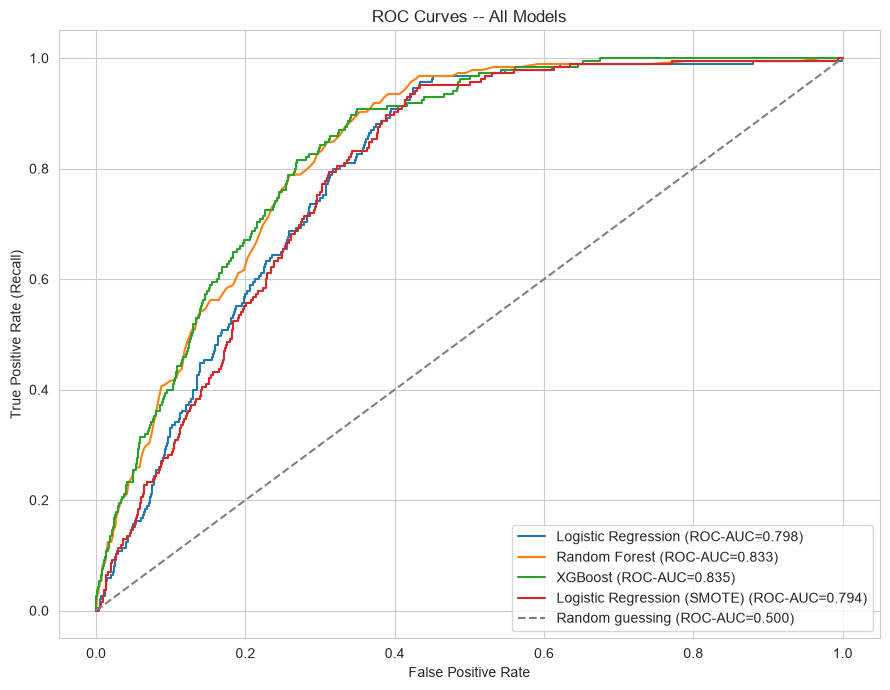

In [27]:
fig, ax = plt.subplots(figsize=(9, 7))

for name, model in models.items():
    X_eval = get_test_features(name)
    y_proba = model.predict_proba(X_eval)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_score = roc_auc_score(y_test, y_proba)
    ax.plot(fpr, tpr, label=f"{name} (ROC-AUC={roc_score:.3f})")

ax.plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random guessing (ROC-AUC=0.500)')
ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate (Recall)')
ax.set_title('ROC Curves -- All Models')
ax.legend()
plt.tight_layout()
plt.show()

### 8.2 Confusion Matrices

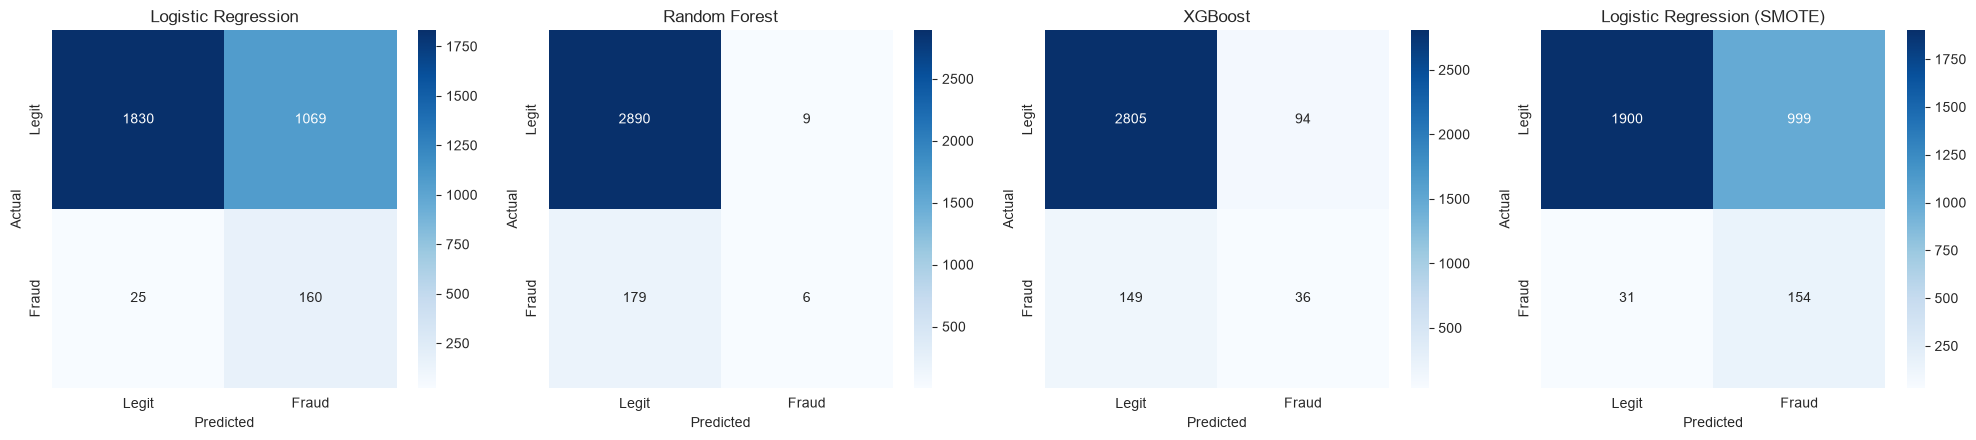

In [28]:
n_models = len(models)
fig, axes = plt.subplots(1, n_models, figsize=(5 * n_models, 4.5))
if n_models == 1:
    axes = [axes]

for ax, (name, model) in zip(axes, models.items()):
    X_eval = get_test_features(name)
    y_pred = model.predict(X_eval)
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Legit', 'Fraud'], yticklabels=['Legit', 'Fraud'])
    ax.set_title(name)
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')

plt.tight_layout()
plt.show()

### 8.3 Decision Threshold Analysis

The default 0.5 probability cutoff is fairly arbitrary. Here we look at precision/recall at a few other thresholds for the best model (by ROC-AUC), since in practice a fraud team might want to shift this threshold deliberately - catch more fraud at the cost of more false alarms, or the other way around.

In [29]:
best_model_name = eval_df.iloc[0]['Model']
best_model = models[best_model_name]
X_eval_best = get_test_features(best_model_name)
y_proba_best = best_model.predict_proba(X_eval_best)[:, 1]

print(f"Best model by ROC-AUC: {best_model_name}\n")

threshold_results = []
for threshold in [0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    y_pred_t = (y_proba_best >= threshold).astype(int)
    threshold_results.append({
        'Threshold': threshold,
        'Precision': precision_score(y_test, y_pred_t, zero_division=0),
        'Recall': recall_score(y_test, y_pred_t, zero_division=0),
        'F1': f1_score(y_test, y_pred_t, zero_division=0),
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df.round(4)

Best model by ROC-AUC: XGBoost



,Threshold,Precision,Recall,F1
0,0.2,0.2154,0.3622,0.2702
1,0.3,0.2458,0.3135,0.2755
2,0.4,0.2389,0.2324,0.2356
3,0.5,0.2769,0.1946,0.2286
4,0.6,0.2990,0.1568,0.2057
5,0.7,0.3099,0.1189,0.1719
6,0.8,0.3462,0.0973,0.1519


## 9. Model Interpretation

### 9.1 Logistic Regression Coefficients

The sign and size of each coefficient shows exactly how that feature pushes a prediction toward or away from fraud, which is the kind of clear "why" tree-based models don't give you directly.

C:\Users\HP\AppData\Local\Temp\ipykernel_23468\3425277975.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='coefficient', y='feature', data=coef_df, palette=colors, ax=ax)


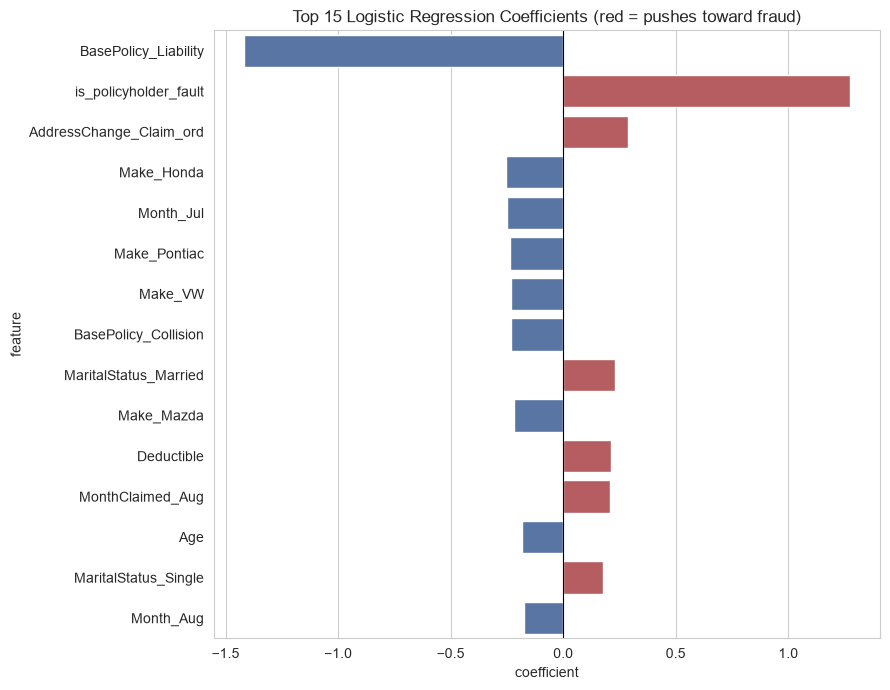

In [30]:
logreg = models['Logistic Regression']
coef_df = pd.DataFrame({
    'feature': X.columns,
    'coefficient': logreg.coef_[0]
}).sort_values('coefficient', key=abs, ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 7))
colors = ['#C44E52' if c > 0 else '#4C72B0' for c in coef_df['coefficient']]
sns.barplot(x='coefficient', y='feature', data=coef_df, palette=colors, ax=ax)
ax.set_title('Top 15 Logistic Regression Coefficients (red = pushes toward fraud)')
ax.axvline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.show()

### 9.2 Random Forest Feature Importance (Cross-Check)

If Random Forest independently ranks roughly the same features as important, that's a good sign the signal is real rather than something specific to how Logistic Regression happens to weight things.

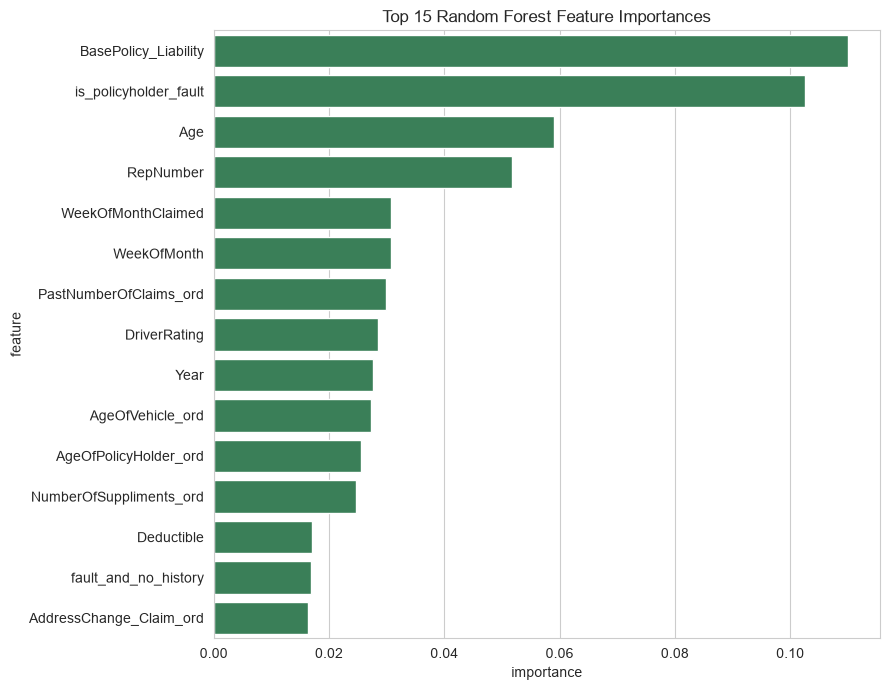

In [31]:
rf = models['Random Forest']
importance_df = pd.DataFrame({
    'feature': X.columns,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False).head(15)

fig, ax = plt.subplots(figsize=(9, 7))
sns.barplot(x='importance', y='feature', data=importance_df, color='seagreen', ax=ax)
ax.set_title('Top 15 Random Forest Feature Importances')
plt.tight_layout()
plt.show()

### 9.3 Error Counts: False Negatives vs False Positives

A recall number on its own doesn't tell you how many actual mistakes that translates to, so we just count both error types directly for the best model.

In [32]:
y_pred_best = (y_proba_best >= 0.5).astype(int)

false_negative_count = ((y_test.values == 1) & (y_pred_best == 0)).sum()
false_positive_count = ((y_test.values == 0) & (y_pred_best == 1)).sum()

print(f"False Negatives (missed fraud): {false_negative_count}")
print(f"False Positives (false alarms): {false_positive_count}")

False Negatives (missed fraud): 149
False Positives (false alarms): 94


## 10. Summary & Findings

**Data quality issues found and fixed:**
- 1 corrupted record (`MonthClaimed`/`DayOfWeekClaimed == '0'`), dropped.
- 320 rows (2.1%) with masked-missing `Age == 0`, fixed using the `AgeOfPolicyHolder` bracket (all fell in "16 to 17").
- 8 columns storing ordinal concepts as free-text bins, converted to proper ordinal encodings.
- 4,987 rows (32.3%) where `VehicleCategory` disagreed with `PolicyType`, resolved by trusting `PolicyType`'s version since it matched `BasePolicy` perfectly.

**What the EDA showed:**
- Fraud rate: 5.99% of claims, a realistic imbalance for insurance fraud.
- Policyholder-at-fault claims are fraudulent about 9x more often than third-party-fault claims (7.89% vs 0.88%).
- Sport/Utility vehicles have roughly double the fraud rate of Sedans.
- `VehiclePrice` has a U-shaped relationship with fraud, which is why we engineered a feature around it.

**Modeling:**
- Compared three models (Logistic Regression, Random Forest, XGBoost/HistGradientBoosting), all using class weighting as the primary way to handle the imbalance, plus one SMOTE variant for comparison.
- Used ROC-AUC as the main metric given the imbalance; full results are in Section 8.
- Picked the best model by ROC-AUC and looked at how precision/recall trade off at different thresholds.
